In [1]:
# ============================================================
# Step 0: Imports and Configuration
# ============================================================

import os
import warnings
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    print("XGBoost available")
except ImportError:
    HAS_XGB = False
    print("XGBoost not installed. Run: pip install xgboost")

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HAS_OPTUNA = True
    print("Optuna available")
except ImportError:
    HAS_OPTUNA = False
    print("Optuna not installed. Run: pip install optuna")

import shap

# Global Configurations
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

DATA_PATH = "gym_ghosts_master.csv"
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nConfiguration done.")
print("Data path:", DATA_PATH)
print("Output dir:", OUTPUT_DIR)

XGBoost available
Optuna available

Configuration done.
Data path: gym_ghosts_master.csv
Output dir: outputs


In [2]:
# ============================================================
# Step 1: Data Loading
# ============================================================

df = pd.read_csv(DATA_PATH)

# 1. Quick structure check
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

# 2. Target variable distribution
target_counts = df["churned_by_february"].value_counts()
target_pct = df["churned_by_february"].value_counts(normalize=True) * 100

print("\nTarget Distribution (churned_by_february):")
for val, count in target_counts.items():
    label = "Churned" if val == 1 else "Retained"
    print(f"  {label:8s} (Class {val}): {count:5d} ({target_pct[val]:.2f}%)")

# 3. Compact preview of key columns
print("\nData Preview:")
display(df[['age', 'distance_km', 'contract_type', 'week1_visits', 'week4_visits', 'churned_by_february']].head())

Dataset Shape: 50000 rows, 24 columns
Missing Values: 0
Duplicate Rows: 0

Target Distribution (churned_by_february):
  Retained (Class 0): 27440 (54.88%)
  Churned  (Class 1): 22560 (45.12%)

Data Preview:


,age,distance_km,contract_type,week1_visits,week4_visits,churned_by_february
0,40,6.6,6_month,3,1,1
1,55,3.8,month_to_month,2,2,1
2,26,3.9,annual,1,0,1
3,20,0.4,annual,6,3,0
4,47,0.4,month_to_month,1,1,1


Dataset shape: (50000, 24)

Numerical columns (20):
['age', 'distance_km', 'prior_gym_experience', 'joined_with_friend', 'monthly_fee_usd', 'signup_week_january', 'promo_used', 'goal_aggressiveness', 'week1_visits', 'week2_visits', 'week3_visits', 'week4_visits', 'avg_weekly_classes', 'booked_induction', 'personal_trainer', 'app_installed', 'avg_session_minutes', 'guest_passes_used', 'locker_rented', 'churned_by_february']

Categorical columns (4):
['member_id', 'sex', 'contract_type', 'primary_goal']

Target: churned_by_february
                     Count    Pct
churned_by_february              
0                    27440  54.88
1                    22560  45.12

Categorical feature distributions

sex:
sex
F        24548
M        24499
Other      953
Name: count, dtype: int64
  Churn rate by sex:
sex
F        0.4503
M        0.4513
Other    0.4722
Name: churned_by_february, dtype: float64

contract_type:
contract_type
month_to_month    31220
6_month           11363
annual             

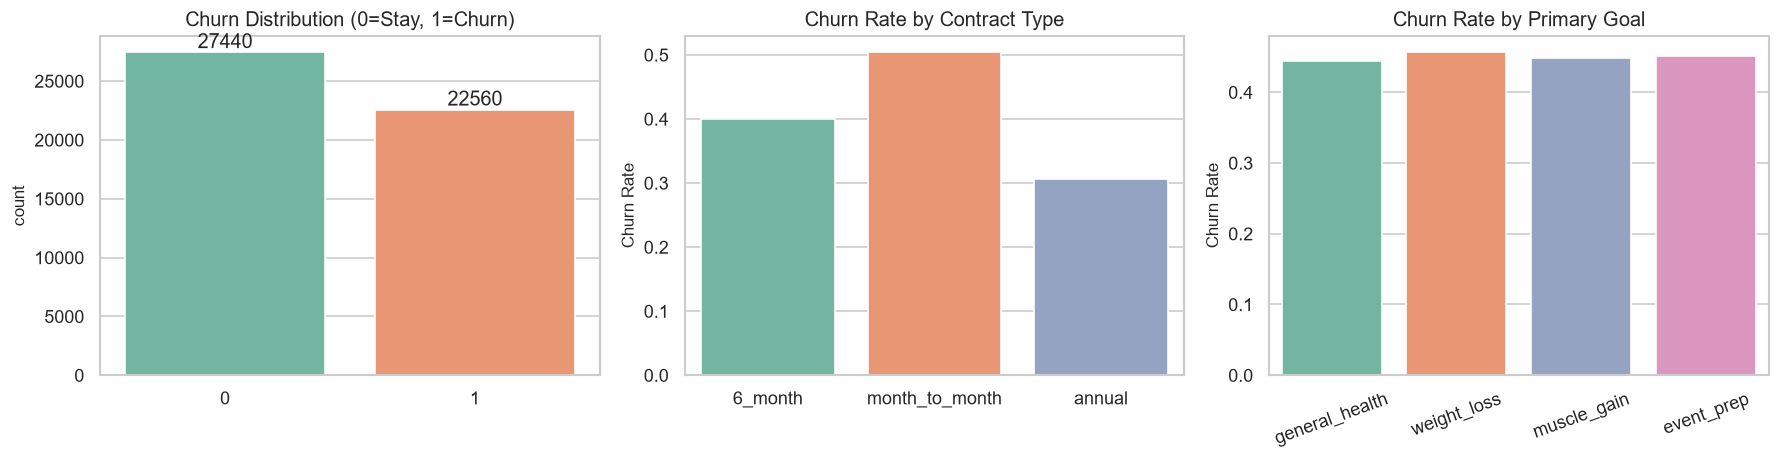

In [3]:
# ============================================================
# Step 2: Data Overview
# ============================================================

# ------------------------------------------------------------
# 2.1 Basic structure
# ------------------------------------------------------------
print("=" * 60)
print("Dataset shape:", df.shape)
print("=" * 60)

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()

print(f"\nNumerical columns ({len(num_cols)}):")
print(num_cols)
print(f"\nCategorical columns ({len(cat_cols)}):")
print(cat_cols)

# ------------------------------------------------------------
# 2.2 Target distribution
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("Target: churned_by_february")
print("=" * 60)
target_counts = df["churned_by_february"].value_counts()
target_pct = df["churned_by_february"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Count": target_counts, "Pct": target_pct.round(2)}))

# ------------------------------------------------------------
# 2.3 Categorical value counts
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("Categorical feature distributions")
print("=" * 60)
for col in cat_cols:
    if col == "member_id":
        continue
    print(f"\n{col}:")
    print(df[col].value_counts())
    print(f"  Churn rate by {col}:")
    print(df.groupby(col)["churned_by_february"].mean().round(4))

# ------------------------------------------------------------
# 2.4 Numerical summary
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("Numerical feature summary")
print("=" * 60)
print(df[num_cols].describe().T.round(3))

# ------------------------------------------------------------
# 2.5 Visualization
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Target distribution
sns.countplot(data=df, x="churned_by_february", ax=axes[0], palette="Set2")
axes[0].set_title("Churn Distribution (0=Stay, 1=Churn)")
axes[0].set_xlabel("")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}",
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

# Contract type vs churn
sns.barplot(data=df, x="contract_type", y="churned_by_february",
            ax=axes[1], palette="Set2", errorbar=None)
axes[1].set_title("Churn Rate by Contract Type")
axes[1].set_ylabel("Churn Rate")
axes[1].set_xlabel("")

# Primary goal vs churn
sns.barplot(data=df, x="primary_goal", y="churned_by_february",
            ax=axes[2], palette="Set2", errorbar=None)
axes[2].set_title("Churn Rate by Primary Goal")
axes[2].set_ylabel("Churn Rate")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_overview.png"), bbox_inches="tight")
plt.show()

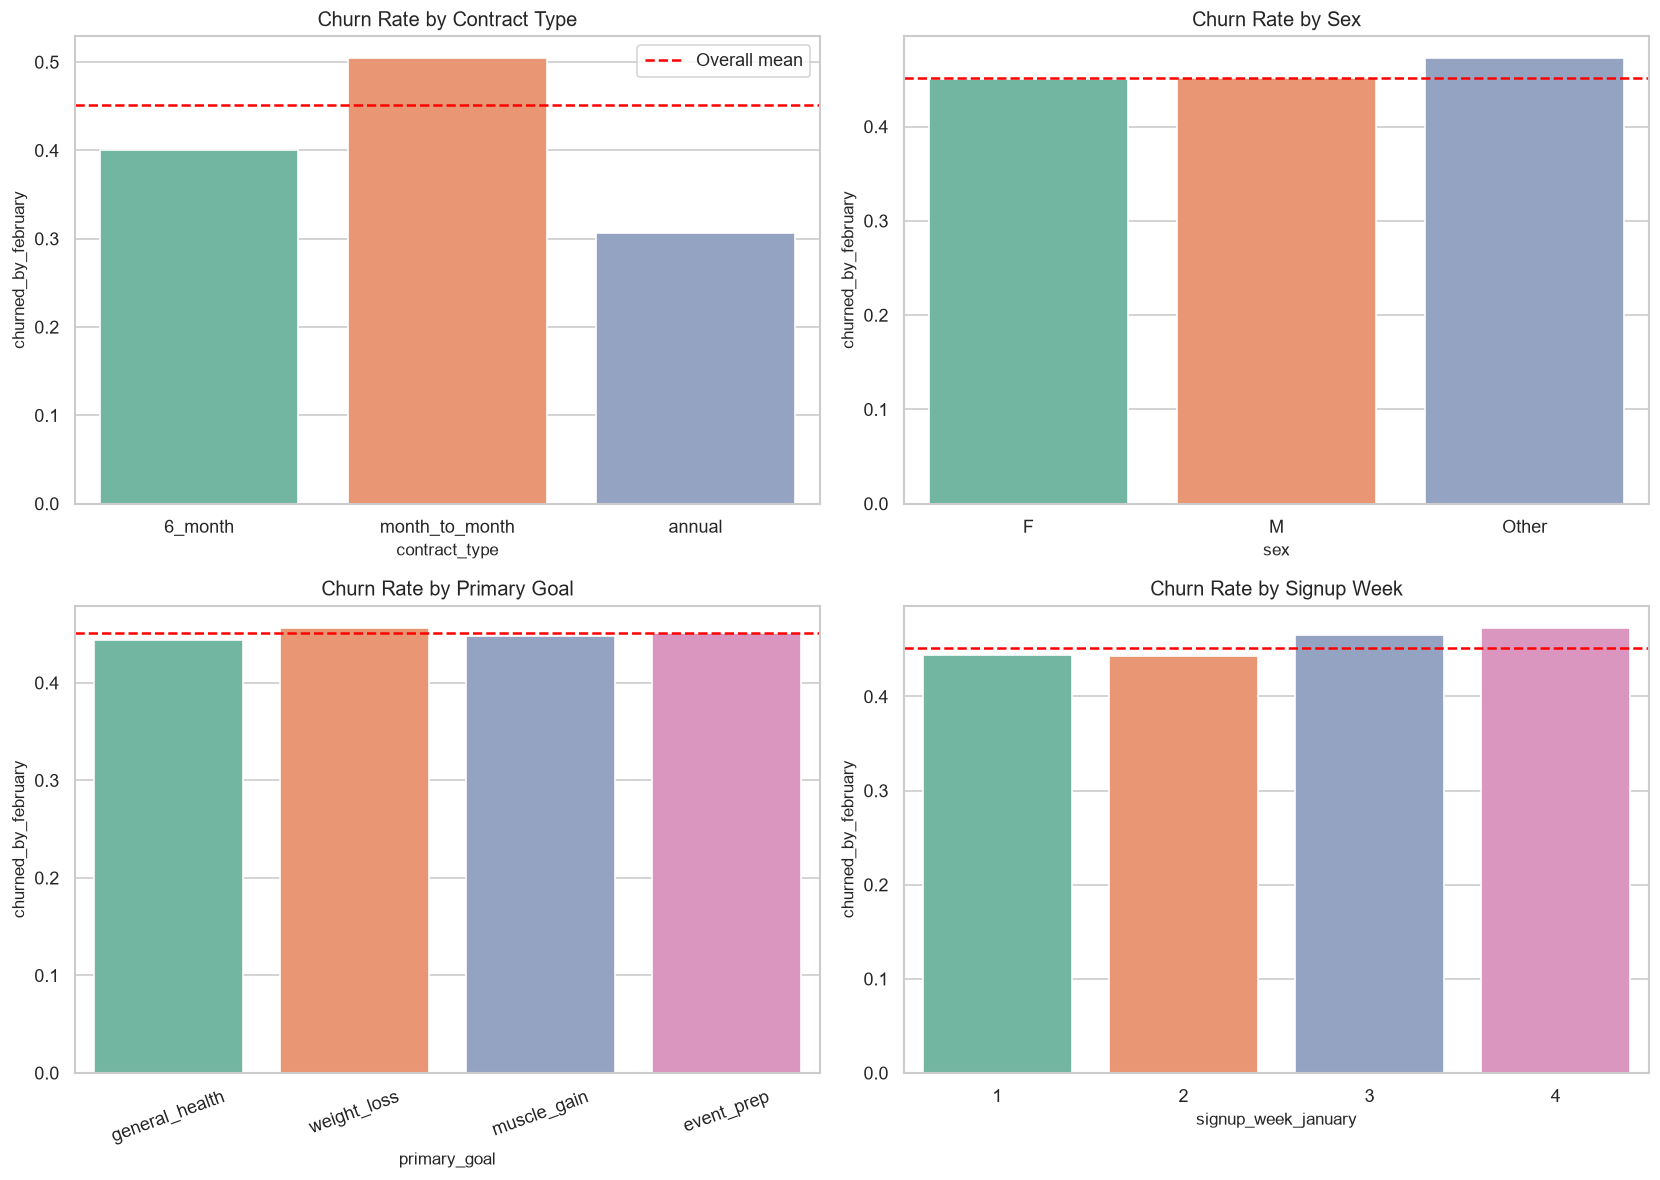

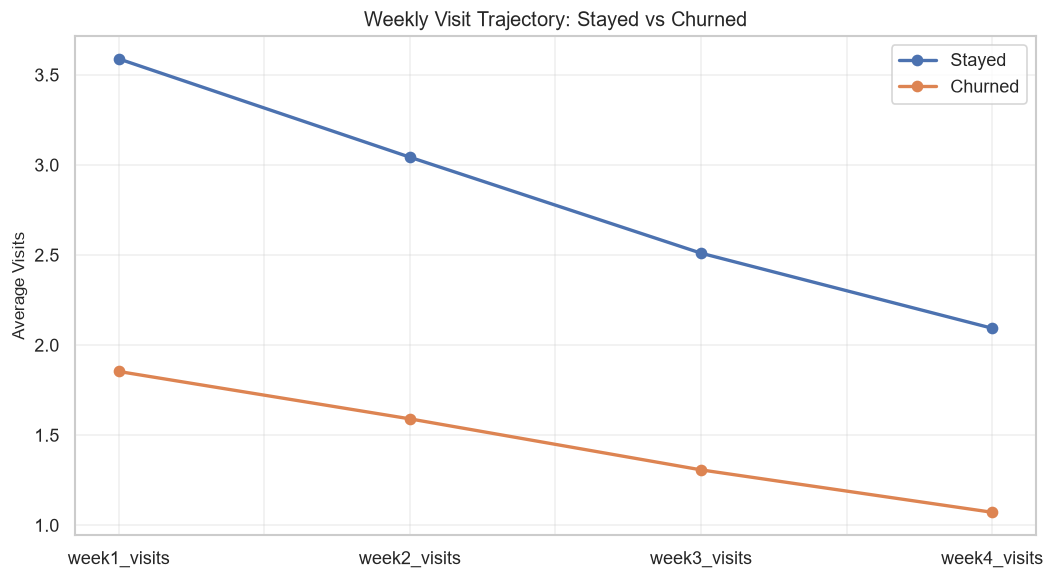

Visit means by churn status:
              Stayed  Churned
week1_visits   3.588    1.853
week2_visits   3.042    1.590
week3_visits   2.510    1.307
week4_visits   2.093    1.071


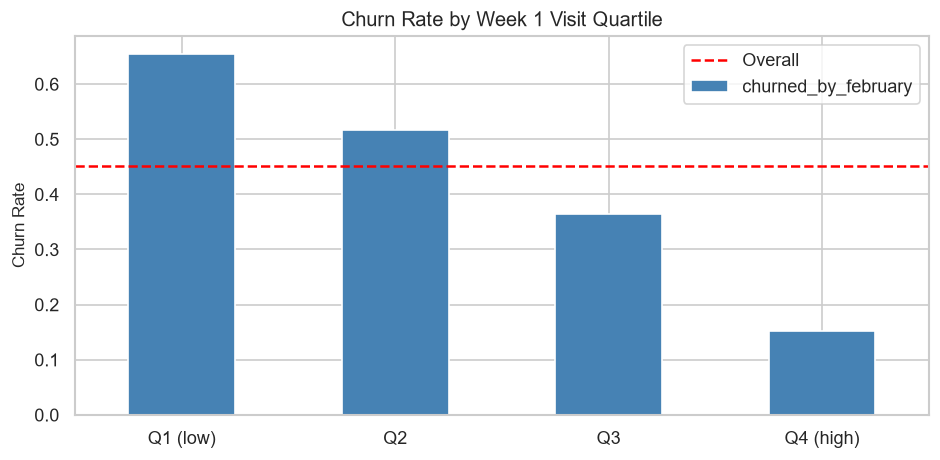


Churn rate by week1 quartile:
week1_quartile
Q1 (low)     0.6540
Q2           0.5159
Q3           0.3649
Q4 (high)    0.1519
Name: churned_by_february, dtype: float64


In [4]:
# ============================================================
# Step 3: Exploratory Data Analysis
# ============================================================

# ------------------------------------------------------------
# 3.1 Churn rate by key segments
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Contract type
sns.barplot(data=df, x="contract_type", y="churned_by_february",
            ax=axes[0, 0], palette="Set2", errorbar=None)
axes[0, 0].axhline(df["churned_by_february"].mean(),
                   color="red", linestyle="--", label="Overall mean")
axes[0, 0].set_title("Churn Rate by Contract Type")
axes[0, 0].legend()

# Sex
sns.barplot(data=df, x="sex", y="churned_by_february",
            ax=axes[0, 1], palette="Set2", errorbar=None)
axes[0, 1].axhline(df["churned_by_february"].mean(),
                   color="red", linestyle="--")
axes[0, 1].set_title("Churn Rate by Sex")

# Primary goal
sns.barplot(data=df, x="primary_goal", y="churned_by_february",
            ax=axes[1, 0], palette="Set2", errorbar=None)
axes[1, 0].axhline(df["churned_by_february"].mean(),
                   color="red", linestyle="--")
axes[1, 0].set_title("Churn Rate by Primary Goal")
axes[1, 0].tick_params(axis="x", rotation=20)

# Signup week
sns.barplot(data=df, x="signup_week_january", y="churned_by_february",
            ax=axes[1, 1], palette="Set2", errorbar=None)
axes[1, 1].axhline(df["churned_by_february"].mean(),
                   color="red", linestyle="--")
axes[1, 1].set_title("Churn Rate by Signup Week")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_eda_segments.png"),
            bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 3.2 Weekly visit trend by churn status
# ------------------------------------------------------------
visit_cols = ["week1_visits", "week2_visits", "week3_visits", "week4_visits"]

visit_means = df.groupby("churned_by_february")[visit_cols].mean().T
visit_means.columns = ["Stayed", "Churned"]

fig, ax = plt.subplots(figsize=(9, 5))
visit_means.plot(marker="o", ax=ax, linewidth=2)
ax.set_title("Weekly Visit Trajectory: Stayed vs Churned")
ax.set_ylabel("Average Visits")
ax.set_xlabel("")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_visit_trajectory.png"),
            bbox_inches="tight")
plt.show()

print("Visit means by churn status:")
print(visit_means.round(3))

# ------------------------------------------------------------
# 3.3 Churn rate by visit quartile (week1)
# ------------------------------------------------------------
df["week1_quartile"] = pd.qcut(df["week1_visits"], q=4,
                               labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
churn_by_w1 = df.groupby("week1_quartile")["churned_by_february"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
churn_by_w1.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Churn Rate by Week 1 Visit Quartile")
ax.set_ylabel("Churn Rate")
ax.set_xlabel("")
ax.axhline(df["churned_by_february"].mean(),
           color="red", linestyle="--", label="Overall")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_churn_by_w1.png"),
            bbox_inches="tight")
plt.show()

print("\nChurn rate by week1 quartile:")
print(churn_by_w1.round(4))

In [5]:
# ============================================================
# Step 4: Feature Engineering
# ============================================================

# ------------------------------------------------------------
# 4.1 Visit-based features (core signal)
# ------------------------------------------------------------
visit_cols = ["week1_visits", "week2_visits", "week3_visits", "week4_visits"]

# Total and average
df["total_visits_4w"] = df[visit_cols].sum(axis=1)
df["avg_visits_4w"] = df[visit_cols].mean(axis=1)

# Decay features
df["visit_decay"] = df["week1_visits"] - df["week4_visits"]
df["decay_ratio"] = df["week4_visits"] / (df["week1_visits"] + 1e-6)
df["visit_std"] = df[visit_cols].std(axis=1)

# Trend: linear slope across 4 weeks
def visit_slope(row):
    y = row[visit_cols].values.astype(float)
    x = np.arange(4)
    return np.polyfit(x, y, 1)[0]

df["visit_slope"] = df[visit_cols].apply(visit_slope, axis=1)

# Early drop: did they drop in week 2 or 3?
df["drop_w2"] = (df["week2_visits"] < df["week1_visits"]).astype(int)
df["drop_w3"] = (df["week3_visits"] < df["week2_visits"]).astype(int)

# Zero-visit flags (any week with 0 visits)
df["zero_any_week"] = (df[visit_cols] == 0).any(axis=1).astype(int)

print("Visit-based features created:")
print([c for c in df.columns if c.startswith(("visit_", "decay_", "drop_", "zero_", "total_", "avg_visits"))])

# ------------------------------------------------------------
# 4.2 Ratio and engagement features
# ------------------------------------------------------------
# Classes per visit
df["classes_per_visit"] = df["avg_weekly_classes"] / (df["avg_visits_4w"] + 1e-6)

# Session engagement
df["session_x_visits"] = df["avg_session_minutes"] * df["total_visits_4w"]

# Commitment score (binary features combined)
commit_features = ["prior_gym_experience", "joined_with_friend",
                   "booked_induction", "personal_trainer",
                   "app_installed", "locker_rented"]
df["commitment_score"] = df[commit_features].sum(axis=1)

# Contract strength (ordinal)
contract_map = {"month_to_month": 0, "6_month": 1, "annual": 2}
df["contract_strength"] = df["contract_type"].map(contract_map)

# ------------------------------------------------------------
# 4.3 Categorical encoding
# ------------------------------------------------------------
le_sex = LabelEncoder()
df["sex_enc"] = le_sex.fit_transform(df["sex"])

le_goal = LabelEncoder()
df["goal_enc"] = le_goal.fit_transform(df["primary_goal"])

print("\nEncoding mapping:")
print("Sex:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Goal:", dict(zip(le_goal.classes_, le_goal.transform(le_goal.classes_))))

# ------------------------------------------------------------
# 4.4 Define final feature set
# ------------------------------------------------------------
base_numeric = [
    "age", "distance_km", "monthly_fee_usd", "goal_aggressiveness",
    "signup_week_january", "avg_session_minutes", "guest_passes_used"
]
binary_features = [
    "prior_gym_experience", "joined_with_friend", "promo_used",
    "booked_induction", "personal_trainer", "app_installed", "locker_rented"
]
visit_raw = visit_cols
visit_engineered = [
    "total_visits_4w", "avg_visits_4w", "visit_decay", "decay_ratio",
    "visit_std", "visit_slope", "drop_w2", "drop_w3", "zero_any_week"
]
engagement = ["avg_weekly_classes", "classes_per_visit", "session_x_visits"]
encoded_cat = ["sex_enc", "goal_enc", "contract_strength"]
composite = ["commitment_score"]

all_features = (base_numeric + binary_features + visit_raw +
                visit_engineered + engagement + encoded_cat + composite)

print(f"\nTotal features: {len(all_features)}")
print(all_features)

# ------------------------------------------------------------
# 4.5 Build X and y
# ------------------------------------------------------------
X = df[all_features].values
y = df["churned_by_february"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")
print(f"Train churn rate: {y_train.mean():.4f}")
print(f"Test  churn rate: {y_test.mean():.4f}")

Visit-based features created:
['total_visits_4w', 'avg_visits_4w', 'visit_decay', 'decay_ratio', 'visit_std', 'visit_slope', 'drop_w2', 'drop_w3', 'zero_any_week']

Encoding mapping:
Sex: {'F': np.int64(0), 'M': np.int64(1), 'Other': np.int64(2)}
Goal: {'event_prep': np.int64(0), 'general_health': np.int64(1), 'muscle_gain': np.int64(2), 'weight_loss': np.int64(3)}

Total features: 34
['age', 'distance_km', 'monthly_fee_usd', 'goal_aggressiveness', 'signup_week_january', 'avg_session_minutes', 'guest_passes_used', 'prior_gym_experience', 'joined_with_friend', 'promo_used', 'booked_induction', 'personal_trainer', 'app_installed', 'locker_rented', 'week1_visits', 'week2_visits', 'week3_visits', 'week4_visits', 'total_visits_4w', 'avg_visits_4w', 'visit_decay', 'decay_ratio', 'visit_std', 'visit_slope', 'drop_w2', 'drop_w3', 'zero_any_week', 'avg_weekly_classes', 'classes_per_visit', 'session_x_visits', 'sex_enc', 'goal_enc', 'contract_strength', 'commitment_score']

Train: (40000, 34), T

In [6]:
# ============================================================
# Step 5.1: Baseline Model Comparison
# ============================================================

from sklearn.model_selection import cross_val_score

def evaluate_model(model, X_train, y_train, X_test, y_test, name):
    """Train, CV, and evaluate a model."""
    cv = cross_val_score(model, X_train, y_train, cv=5,
                         scoring="roc_auc", n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    return {
        "Model": name,
        "CV_AUC_mean": cv.mean(),
        "CV_AUC_std": cv.std(),
        "Test_AUC": roc_auc_score(y_test, y_proba),
        "Test_Accuracy": accuracy_score(y_test, y_pred),
        "Test_F1": f1_score(y_test, y_pred),
        "Test_Precision": precision_score(y_test, y_pred),
        "Test_Recall": recall_score(y_test, y_pred)
    }

results = []

# Logistic Regression (requires scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=SEED)
results.append(evaluate_model(lr, X_train_scaled, y_train,
                              X_test_scaled, y_test, "Logistic Regression"))

# Random Forest
rf = RandomForestClassifier(n_estimators=300, random_state=SEED,
                            n_jobs=-1)
results.append(evaluate_model(rf, X_train, y_train, X_test, y_test,
                              "Random Forest"))

# XGBoost
if HAS_XGB:
    xgb = XGBClassifier(n_estimators=300, random_state=SEED,
                        eval_metric="logloss", n_jobs=-1)
    results.append(evaluate_model(xgb, X_train, y_train, X_test, y_test,
                                  "XGBoost"))

results_df = pd.DataFrame(results).round(4)
print("=" * 90)
print("Baseline Model Comparison")
print("=" * 90)
print(results_df.to_string(index=False))

Baseline Model Comparison
              Model  CV_AUC_mean  CV_AUC_std  Test_AUC  Test_Accuracy  Test_F1  Test_Precision  Test_Recall
Logistic Regression       0.8294      0.0041    0.8214         0.7384   0.7140          0.7046       0.7236
      Random Forest       0.8183      0.0044    0.8143         0.7372   0.7088          0.7087       0.7090
            XGBoost       0.7973      0.0050    0.7967         0.7228   0.6932          0.6924       0.6939


In [7]:
# ============================================================
# Step 5.2: Optuna Hyperparameter Tuning (XGBoost)
# ============================================================

if HAS_OPTUNA and HAS_XGB:
    from sklearn.model_selection import StratifiedKFold
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 800),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "gamma": trial.suggest_float("gamma", 0, 5),
            "reg_alpha": trial.suggest_float("reg_alpha", 0, 2),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.5, 5),
            "random_state": SEED,
            "eval_metric": "logloss",
            "n_jobs": -1
        }
        
        model = XGBClassifier(**params)
        scores = []
        for train_idx, val_idx in skf.split(X_train, y_train):
            model.fit(X_train[train_idx], y_train[train_idx])
            proba = model.predict_proba(X_train[val_idx])[:, 1]
            scores.append(roc_auc_score(y_train[val_idx], proba))
        return np.mean(scores)
    
    print("Running Optuna (100 trials)...")
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=100, show_progress_bar=True)
    
    print(f"\nBest CV AUC: {study.best_value:.4f}")
    print("Best params:")
    for k, v in study.best_params.items():
        print(f"  {k}: {v}")
    
    # Train final model with best params
    best_xgb = XGBClassifier(**study.best_params, random_state=SEED,
                             eval_metric="logloss", n_jobs=-1)
    best_xgb.fit(X_train, y_train)
    y_proba_best = best_xgb.predict_proba(X_test)[:, 1]
    y_pred_best = best_xgb.predict(X_test)
    
    print(f"\nTuned XGBoost Test AUC: {roc_auc_score(y_test, y_proba_best):.4f}")
    print(f"Tuned XGBoost Test F1:  {f1_score(y_test, y_pred_best):.4f}")
else:
    print("Optuna or XGBoost not available, skipping tuning.")

Running Optuna (100 trials)...


  0%|          | 0/100 [00:00<?, ?it/s]


Best CV AUC: 0.8284
Best params:
  n_estimators: 423
  max_depth: 3
  learning_rate: 0.052542603251580194
  subsample: 0.8073754021171065
  colsample_bytree: 0.6443958529372981
  min_child_weight: 8
  gamma: 4.665911988347323
  reg_alpha: 1.7559401123217586
  reg_lambda: 2.784563552940633

Tuned XGBoost Test AUC: 0.8208
Tuned XGBoost Test F1:  0.7131


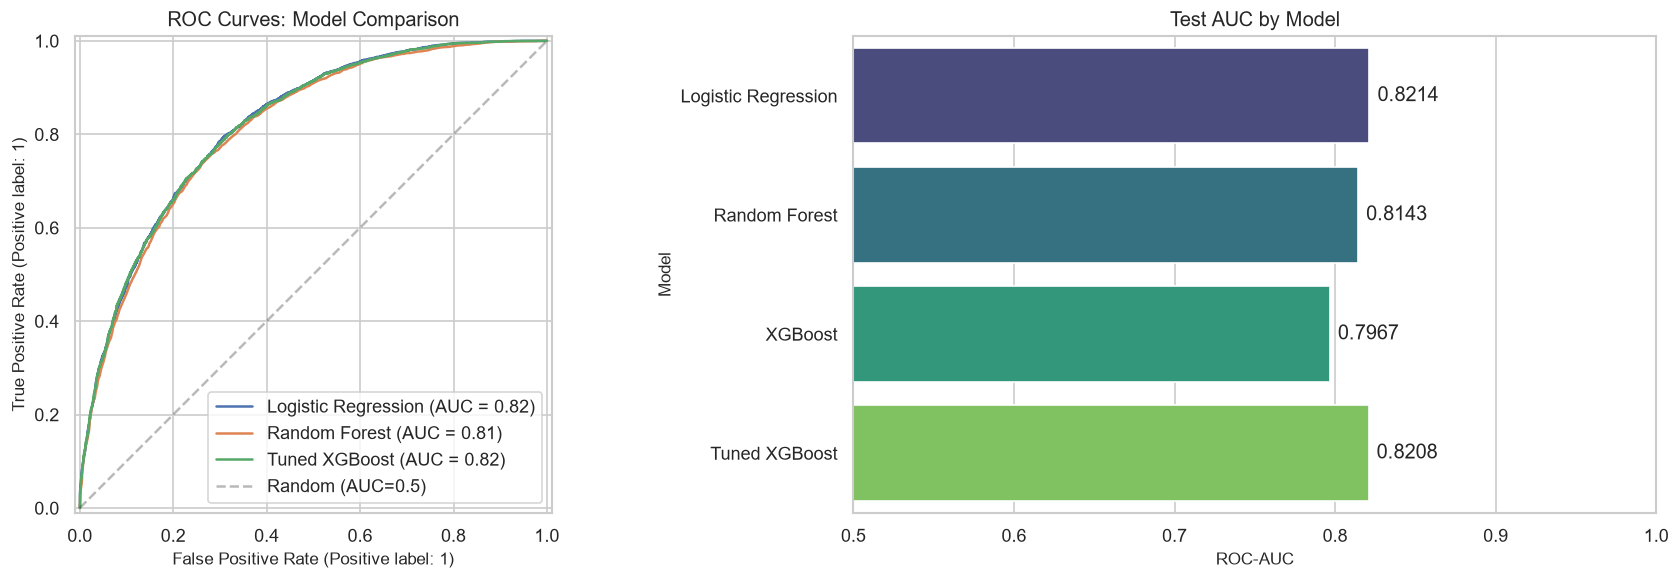

In [9]:
# ============================================================
# Step 5.3: ROC Comparison
# ============================================================
from sklearn.metrics import RocCurveDisplay
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: ROC curves
ax = axes[0]
for model, name, X_use in [
    (lr, "Logistic Regression", X_test_scaled),
    (rf, "Random Forest", X_test),
]:
    model.fit(X_train_scaled if name == "Logistic Regression" else X_train,
              y_train)
    proba = model.predict_proba(X_use)[:, 1]
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)

if HAS_XGB:
    if HAS_OPTUNA:
        RocCurveDisplay.from_predictions(y_test, y_proba_best,
                                         name="Tuned XGBoost", ax=ax)
    else:
        RocCurveDisplay.from_predictions(
            y_test, xgb.predict_proba(X_test)[:, 1],
            name="XGBoost", ax=ax)

ax.plot([0, 1], [0, 1], "k--", alpha=0.3, label="Random (AUC=0.5)")
ax.set_title("ROC Curves: Model Comparison")
ax.legend(loc="lower right")

# Right: AUC bar chart
ax = axes[1]
plot_df = results_df[["Model", "Test_AUC"]].copy()
if HAS_OPTUNA and HAS_XGB:
    plot_df = pd.concat([plot_df, pd.DataFrame([{
        "Model": "Tuned XGBoost",
        "Test_AUC": roc_auc_score(y_test, y_proba_best)
    }])], ignore_index=True)

sns.barplot(data=plot_df, x="Test_AUC", y="Model", ax=ax,
            palette="viridis")
ax.set_xlim(0.5, 1.0)
ax.set_title("Test AUC by Model")
for i, v in enumerate(plot_df["Test_AUC"]):
    ax.text(v + 0.005, i, f"{v:.4f}", va="center")
ax.set_xlabel("ROC-AUC")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_model_comparison.png"),
            bbox_inches="tight")
plt.show()

SHAP values shape: (3000, 34)
Expected value (base): -0.1991

Top 15 features by mean |SHAP|:
            Feature  Mean_SHAP
    total_visits_4w   0.468116
 avg_weekly_classes   0.348268
      avg_visits_4w   0.329450
  contract_strength   0.251420
        distance_km   0.244254
   commitment_score   0.173792
goal_aggressiveness   0.163417
   session_x_visits   0.162367
  classes_per_visit   0.114134
    monthly_fee_usd   0.109019
                age   0.069154
   booked_induction   0.062875
signup_week_january   0.043509
      app_installed   0.036425
   personal_trainer   0.036114


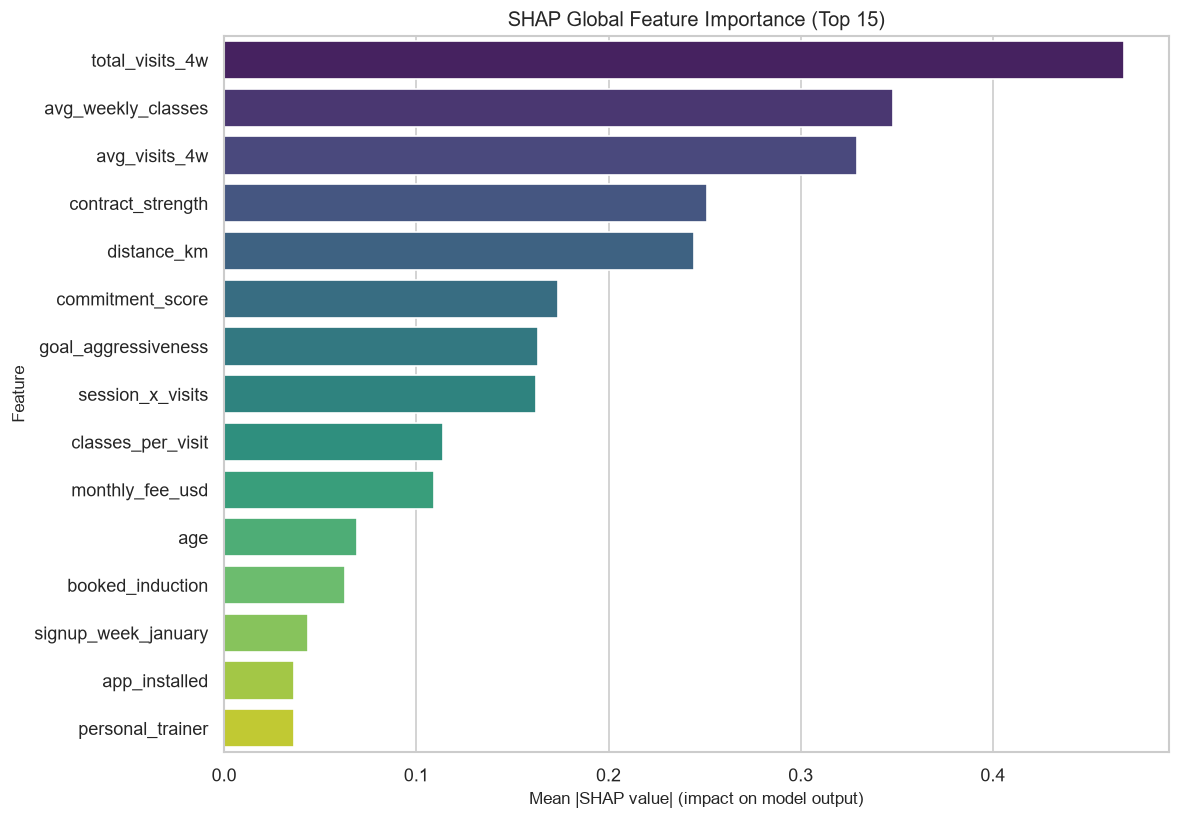

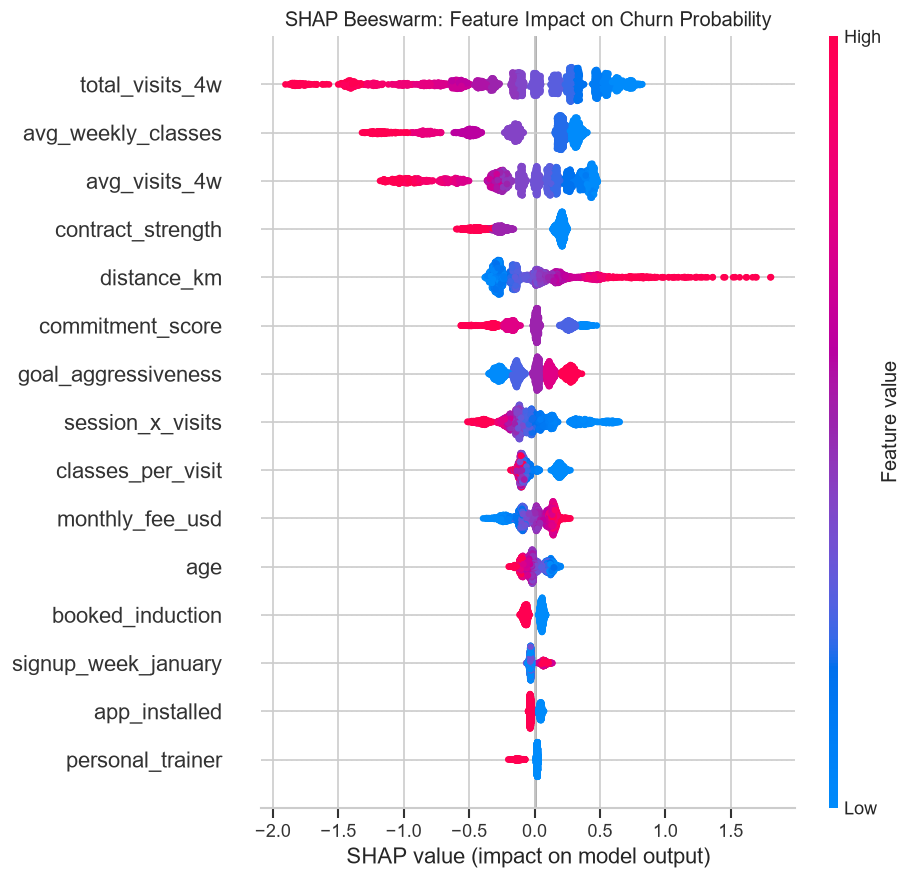

<Figure size 1080x600 with 0 Axes>

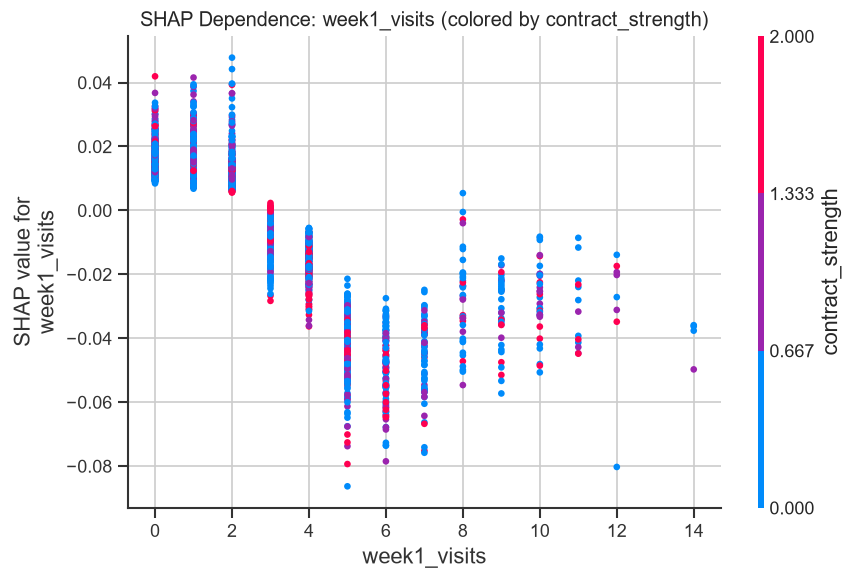

High-risk member (churn prob = 0.9671):
  week1_visits: 1
  total_visits_4w: 3.0
  contract_strength: 0


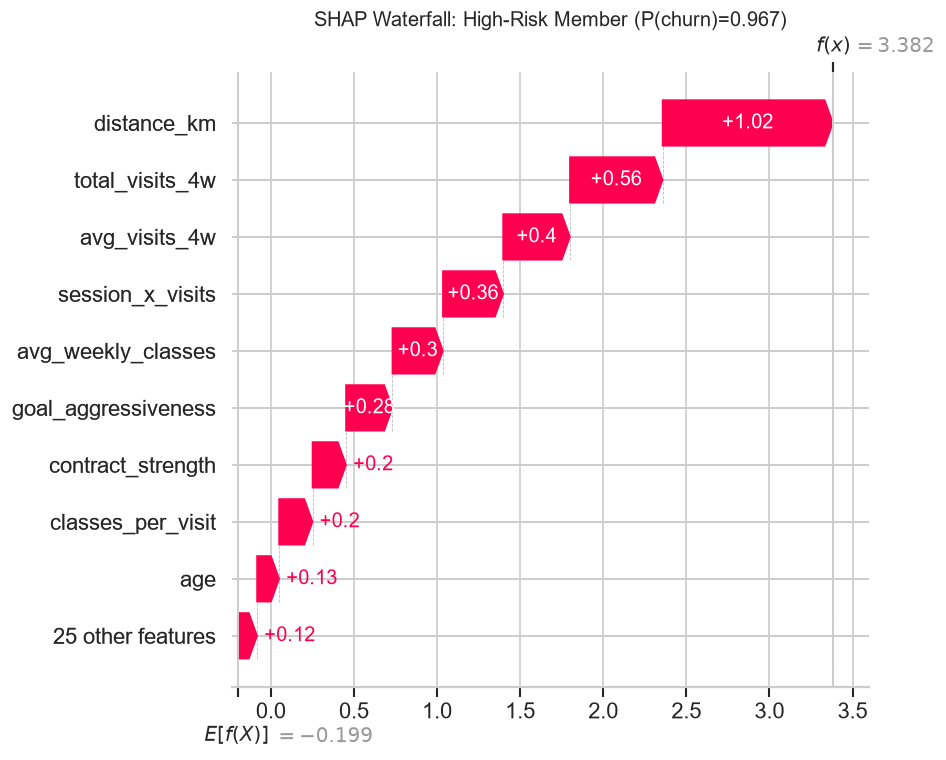

In [10]:
# ============================================================
# Step 6: SHAP Interpretability Analysis
# ============================================================

import shap

# Use tuned XGBoost for SHAP (best performance)
explainer = shap.TreeExplainer(best_xgb)

# Use a sample of test set for speed
X_sample = X_test[:3000]
shap_values = explainer.shap_values(X_sample)

print(f"SHAP values shape: {shap_values.shape}")
print(f"Expected value (base): {explainer.expected_value:.4f}")

# ------------------------------------------------------------
# 6.1 Global Feature Importance (Mean |SHAP|)
# ------------------------------------------------------------
shap_importance = pd.DataFrame({
    "Feature": all_features,
    "Mean_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values("Mean_SHAP", ascending=False)

print("\nTop 15 features by mean |SHAP|:")
print(shap_importance.head(15).to_string(index=False))

# Plot
plt.figure(figsize=(10, 7))
sns.barplot(data=shap_importance.head(15), x="Mean_SHAP", y="Feature",
            palette="viridis")
plt.title("SHAP Global Feature Importance (Top 15)")
plt.xlabel("Mean |SHAP value| (impact on model output)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_shap_global.png"),
            bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6.2 SHAP Beeswarm (individual-level)
# ------------------------------------------------------------
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_sample,
                  feature_names=all_features, show=False,
                  max_display=15)
plt.title("SHAP Beeswarm: Feature Impact on Churn Probability")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_shap_beeswarm.png"),
            bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6.3 SHAP Dependence: week1_visits
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))
shap.dependence_plot("week1_visits", shap_values, X_sample,
                     feature_names=all_features,
                     interaction_index="contract_strength",
                     show=False)
plt.title("SHAP Dependence: week1_visits (colored by contract_strength)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_shap_dependence_w1.png"),
            bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6.4 SHAP Waterfall: individual prediction
# ------------------------------------------------------------
from shap import Explanation

# Find high-churn-risk member WITHIN the SHAP sample (first 3000)
proba_sample = best_xgb.predict_proba(X_sample)[:, 1]
high_risk_idx = np.argmax(proba_sample)

print(f"High-risk member (churn prob = {proba_sample[high_risk_idx]:.4f}):")
print(f"  week1_visits: {X_sample[high_risk_idx, all_features.index('week1_visits')]:.0f}")
print(f"  total_visits_4w: {X_sample[high_risk_idx, all_features.index('total_visits_4w')]:.1f}")
print(f"  contract_strength: {X_sample[high_risk_idx, all_features.index('contract_strength')]:.0f}")

shap.waterfall_plot(
    Explanation(shap_values[high_risk_idx],
                explainer.expected_value,
                feature_names=all_features),
    show=False, max_display=10
)
plt.title(f"SHAP Waterfall: High-Risk Member (P(churn)={proba_sample[high_risk_idx]:.3f})")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_shap_waterfall.png"),
            bbox_inches="tight")
plt.show()

Optimal threshold: 0.120
Min expected cost: $90,480
At default 0.5:    $216,710


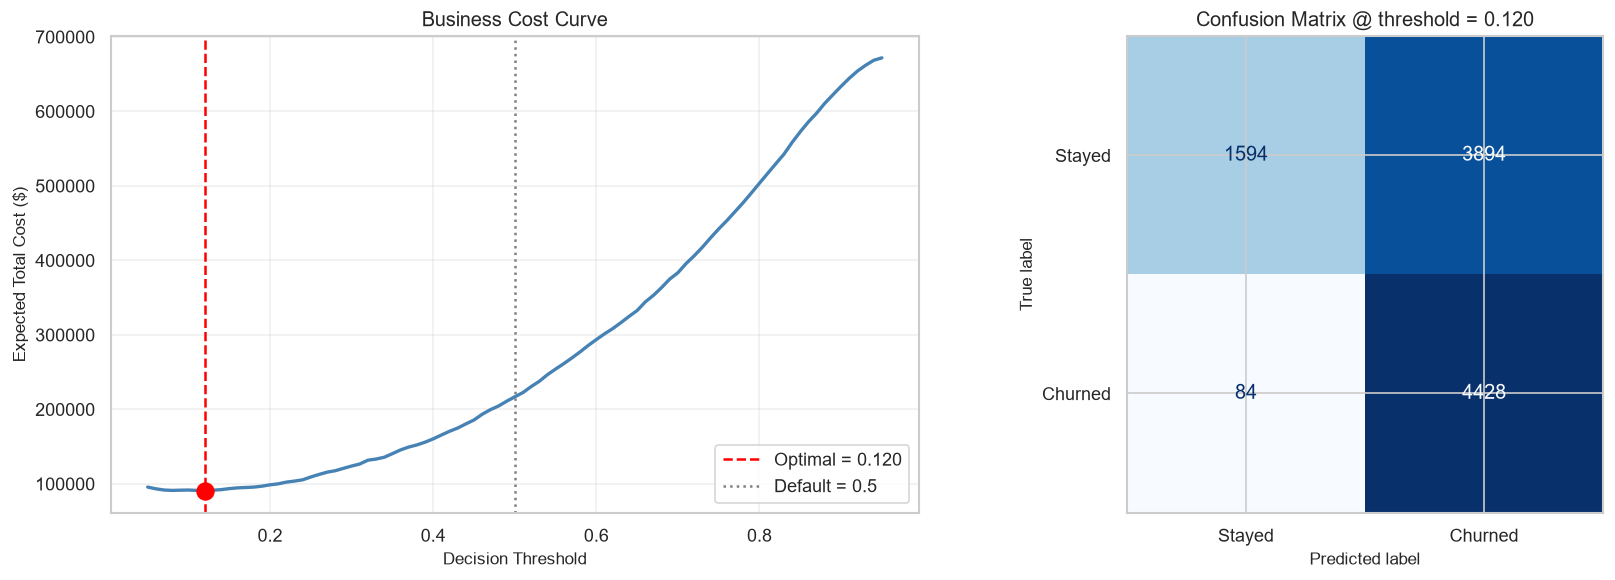


Threshold Comparison

Default (threshold=0.500):
  Precision: 0.7066  |  Recall: 0.7196  |  F1: 0.7131
  TP=3247, FP=1348, FN=1265, TN=4140
  Expected Cost: $216,710

Optimized (threshold=0.120):
  Precision: 0.5321  |  Recall: 0.9814  |  F1: 0.6900
  TP=4428, FP=3894, FN=84, TN=1594
  Expected Cost: $90,480

Results saved to: outputs


In [11]:
# ============================================================
# Step 7: Business-Aware Threshold Optimization
# ============================================================

# Business cost assumptions
cost_fn = 150   # missed churner (lost LTV)
cost_fp = 20    # wasted retention offer (discount cost)

thresholds = np.linspace(0.05, 0.95, 91)
expected_costs = []

for thr in thresholds:
    y_pred_thr = (y_proba_best >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thr).ravel()
    total_cost = fn * cost_fn + fp * cost_fp
    expected_costs.append(total_cost)

# Find optimal threshold
optimal_idx = np.argmin(expected_costs)
optimal_thr = thresholds[optimal_idx]
min_cost = expected_costs[optimal_idx]

print(f"Optimal threshold: {optimal_thr:.3f}")
print(f"Min expected cost: ${min_cost:,.0f}")
print(f"At default 0.5:    ${expected_costs[np.argmin(np.abs(thresholds-0.5))]:,.0f}")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
ax.plot(thresholds, expected_costs, color="steelblue", linewidth=2)
ax.axvline(optimal_thr, color="red", linestyle="--",
           label=f"Optimal = {optimal_thr:.3f}")
ax.axvline(0.5, color="gray", linestyle=":", label="Default = 0.5")
ax.scatter(optimal_thr, min_cost, color="red", s=100, zorder=5)
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Expected Total Cost ($)")
ax.set_title("Business Cost Curve")
ax.legend()
ax.grid(True, alpha=0.3)

y_pred_opt = (y_proba_best >= optimal_thr).astype(int)
cm = confusion_matrix(y_test, y_pred_opt)
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(
    ax=axes[1], cmap="Blues", colorbar=False
)
axes[1].set_title(f"Confusion Matrix @ threshold = {optimal_thr:.3f}")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_business_threshold.png"), bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Final report: default vs optimized
# ------------------------------------------------------------
from sklearn.metrics import precision_recall_fscore_support

def report_at_threshold(thr, label):
    y_pred_thr = (y_proba_best >= thr).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred_thr, average="binary")
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thr).ravel()
    cost = fn * cost_fn + fp * cost_fp
    print(f"\n{label} (threshold={thr:.3f}):")
    print(f"  Precision: {prec:.4f}  |  Recall: {rec:.4f}  |  F1: {f1:.4f}")
    print(f"  TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    print(f"  Expected Cost: ${cost:,.0f}")

print("\n" + "=" * 60)
print("Threshold Comparison")
print("=" * 60)
report_at_threshold(0.5, "Default")
report_at_threshold(optimal_thr, "Optimized")

# Save artifacts
results_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)
shap_importance.to_csv(os.path.join(OUTPUT_DIR, "shap_importance.csv"), index=False)
print("\nResults saved to:", OUTPUT_DIR)